# Lab Report - Interpolation

### Problem Statement: 
##### Choose a cambered airfoil NACA-abcd. For a given number of points on the airfoil geometry (N), reconstruct a smooth airfoil surface.

##### Stages: 
    1) Use a random number generator in NumPy to choose the maximum camber, the location of maximum camber and the percentage of thickness to chord.
    2) Write a function to plot a cambered airfoil.
    3) Write a function "Lagrng". Use the function 'Lagrng()' to reconstruct the airfoil.
    4) Plot the original airfoil and the reconstructed one.
    5) Quantify the error (max, RMS) between the true and reconstructed results.
    6) Document how the results can be improved by choosing the spacing between data points.
    7) Reconstruct the airfoil using cubic splines and quantify the errors. This requires writing a Python function for cubic spline interpolation.

### Approach and numerical method

#### 1) Random Number Generator:
The random number option in NumPy is used to create random numbers for the NACA airfoil.\
    In the case of the NACA 4-digit series, we need 3 such numbers, as the airfoil nomenclature uses\
    **1st** digit for max camber as a percentage of the chord,\
    **2nd** digit for location of max camber from the leading edge in tenths of chord,\
    **last 2** digits indicating the thickness as a percentage of the chord

 The random numbers were generated and stored in the respective variables, namely
   
 ```python
#For ease of use
m = Max_camber
p = Max_c_location
t = Thickness
```

    

#### 2) Writing a function to plot a cambered airfoil.

 If we think in reverse chronology, in the end we need the X, Y coordinates, which would start from the leading edge of the airfoil/
and trace the curve to the trailing edge through the upper surface, then back to the leading edge via the lower surface in one go.

   1) We need coordinates of x,y for the upper and lower surfaces. Then we need to concatenate them after flipping the coordinates of the lower surface
   2) Since the airfoil has a camber line, we need a function that evaluates Y_c (camber line) for the given value of x
   3) Then, again, a secondary function that evaluates the change in Y due to Y_c.

    


##### Thickness Distribution

$$y_t=5t(0.2969\sqrt{x}-0.1260x-0.3516x^2+0.2843x^3-0.1015x^4)$$

##### Mean Camber Line

$0\leq x\leq p$
$$y_c=\frac{m}{p^2}\left(2px-x^2\right)$$

$p\leq x\leq1$
$$y_c=\frac{m}{(1-p)^2}\left(1-2p+2px-x^2\right)$$

##### Camber Line Slope

For $0\leq x\leq p$
$$\frac{dy_c}{dx}=\frac{2m}{p^2}(p-x)$$

For $p\leq x\leq1$
$$\frac{dy_c}{dx}=\frac{2m}{(1-p)^2}(p-x)$$

##### Surface Coordinates

$$\theta=\tan^{-1}\left(\frac{dy_c}{dx}\right)$$

$$x_u=x-y_t\sin\theta$$
$$y_u=y_c+y_t\cos\theta$$

$$x_l=x+y_t\sin\theta$$
$$y_l=y_c-y_t\cos\theta$$

#### 3) Interpolation function lagrng()

##### Lagrange Interpolation Polynomial

Given $n$ data points $(x_i,y_i)$, the Lagrange polynomial is

$$P(x)=\sum_{i=0}^{n-1}y_iL_i(x)$$

where the Lagrange basis polynomial is

$$L_i(x)=\prod_{\substack{j=0\\j\neq i}}^{n-1}\frac{x-x_j}{x_i-x_j}$$


#### 4) Cubic spline function 
Defining parameters to write a cubic spline interpolation.

For a given set of coordinates $(x_i,y_i)$, the spline function over the $i$-th interval is

$$
S_i(x)=a_i+b_i(x-x_i)+c_i(x-x_i)^2+d_i(x-x_i)^3
$$

where $a_i$, $b_i$, $c_i$, and $d_i$ are the coefficients of the cubic polynomial for that interval.

$$
h_i=x_{i+1}-x_i
$$

$$
Z_i=S''(x_i)
$$


$
S'_{i}(x_{i}) = S'_{i+1}(x_{i}) 
$

The derivatives are the same at the endpoints to maintain continuity.

$
h_{i-1}Z_{i-1} + 2(h_{i-1}+h_{i})Z_i + h_{i}Z_{i+1}=
6[ \frac{y_{i+1}-y_i}{h_{i}}-\frac{y_i-y_{i-1}}{h_{i-1}}]
$

If h is considered the same, then 

$
hZ_{i-1} + 2(h+h)Z_i + hZ_{i+1}=
\frac{6}{h}[y_{i+1}-2y_i-y_{i-1}]
$

The equations for all interior points can be assembled into a tridiagonal matrix

$$
\mathbf{A}\mathbf{Z}=\mathbf{z}
$$


```python
for i in range(1, n):
    row = i - 1

    A[row, row] = 2 * (h[i - 1] + h[i])

    if i > 1:
        A[row, row - 1] = h[i - 1]

    if i < n - 1:
        A[row, row + 1] = h[i]

    z[row] = 6 * ( (y[i + 1] - y[i]) / h[i] - (y[i] - y[i - 1]) / h[i - 1])
```

Once the second derivatives have been obtained, the coefficients for each interval can be calculated directly.

The coefficients are
$$
a_i=y_i
$$

$$
b_i=
\frac{y_{i+1}-y_i}{h_i}
-\frac{h_i}{6}(2Z_i+Z_{i+1})
$$

$$
c_i=\frac{Z_i}{2}
$$

$$
d_i=\frac{Z_{i+1}-Z_i}{6h_i}
$$



#### Using a random number generator to create NACA-abcd Airfoil.

In [1]:
#generating 3 random numbers for the NACA airfoil
import numpy as np

Max_camber = np.random.randint(2,10)
Max_c_location = np.random.randint(3,6)
Thickness = np.random.randint(10,15)

#print(Max_camber,Max_c_location,Thickness)

Max_camber = Max_camber/100
Max_c_location = Max_c_location/10
Thickness = Thickness/100

print(Max_camber,Max_c_location,Thickness)

#For ease of use
m = Max_camber
p = Max_c_location
t = Thickness

0.06 0.4 0.11


### Writing a function to plot a Cambered NACA Airfoil

In [2]:

x = np.linspace(0, 1, 201) #creating n points for the x axis
#print(x)

# Corresponding y values for the generated x values.
y_t = 5*t*(0.2969*(x**0.5) - 0.1260*(x) - 0.3516*(x**2) + 0.2843*(x**3) - 0.1036*(x**4)) # y_t is thickness value

# evaluating y values for the x to plot the camber line
y_c = np.where(x <= p, (m/p**2) * (2*p*x - x**2), (m/(1-p)**2) * ((1 - 2*p) + 2*p*x - x**2))
#print(y_c)

# Evaluating x,y values for the upper and lower surfaces.
# So that the increment in y value due to the camber is perpendicular to the surface and not just along the y-axis 
d_yc = np.where(x <= p, (2*m/p**2) * (p - x),(2*m/(1-p)**2) * (p - x) )

Theta = np.arctan(d_yc)

x_u = x - y_t*np.sin(Theta)
y_u = y_c + y_t*np.cos(Theta)
x_l = x + y_t*np.sin(Theta)
y_l = y_c - y_t*np.cos(Theta)
#print(x_u,x_l)

x_low = np.flip(x_l)
y_low = np.flip(y_l)
#print(x_l)
X = np.concatenate([x_u,x_low])
Y = np.concatenate([y_u,y_low])
print(X[200],X[401])
#print(X,Y)

1.0 0.0


### Plotting the NACA airfoil using the written function

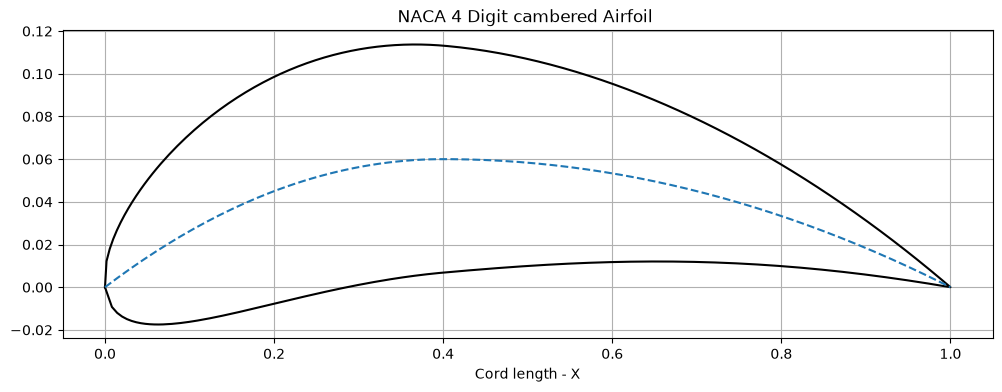

In [3]:

import matplotlib.pyplot as mp
mp.figure(figsize=(12, 4))
mp.plot(X,Y,color='k')
mp.plot(x,y_c,'--')
mp.title('NACA 4 Digit cambered Airfoil ')
mp.xlabel('Cord length - X')
mp.grid()
mp.show()



### Writing a Lagrange function to perform interpolation

In [4]:

def Lagrng(x,y,n,a):
    sum = 0
    for i in range(0,n):
        product = y[i]
        for j in range(0,n):
            if i!= j:
                product = product*(a - x[j])/(x[i] - x[j])
        sum = sum + product
    return(sum)

### Reconstructing the airfoil using Lagrng Function


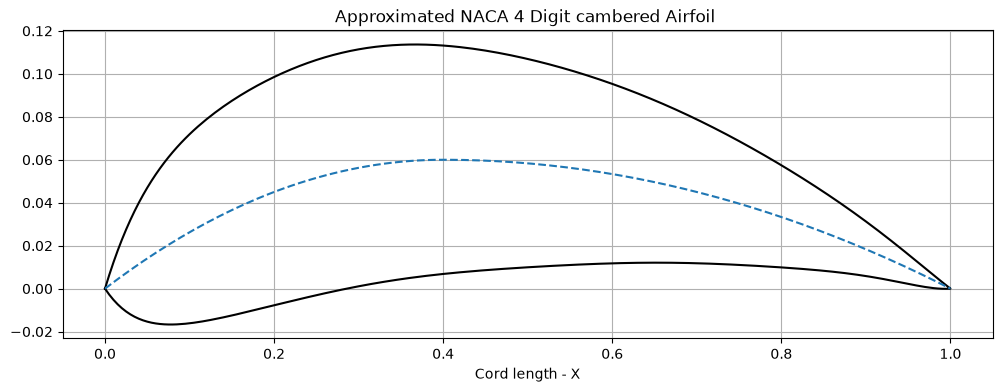

In [5]:

x_upper = np.array([X[0],X[20],X[40],X[60],X[80],X[100],X[120],X[140],X[160],X[180],X[200]])
y_upper = np.array([Y[0],Y[20],Y[40],Y[60],Y[80],Y[100],Y[120],Y[140],Y[160],Y[180],Y[200]])

x_lower = np.array([X[201],X[221],X[241],X[261],X[281],X[301],X[321],X[341],X[361],X[381],X[401]])
y_lower = np.array([Y[201],Y[221],Y[241],Y[261],Y[281],Y[301],Y[321],Y[341],Y[361],Y[381],Y[401]])

Xupper= np.linspace(0,1,201)
Xlower= np.flip(Xupper)

Yupper= Lagrng(x_upper,y_upper,11,Xupper)
Ylower= Lagrng(x_lower,y_lower,11,Xlower)

X_a= np.concatenate([Xupper,Xlower])
Y_a= np.concatenate([Yupper,Ylower])
mp.figure(figsize=(12, 4))
mp.plot(X_a,Y_a,color='k')
mp.plot(x,y_c,'--')
mp.title('Approximated NACA 4 Digit cambered Airfoil ')
mp.xlabel('Cord length - X')
mp.grid()
mp.show()

X_test= np.concatenate([x_upper,x_lower])
Y_test= np.concatenate([y_upper,y_lower])


# x_upper = X[np.arange(0,200,40)]
# y_upper = Y[np.arange(0,200,40)]
# x_lower = X[np.arange(201,401,40)]
# y_lower = Y[np.arange(201,401,40)]

#mp.plot(Xupper,Yupper,'--')
#mp.plot(Xlower,Ylower,'--')
#print(Xupper,Yupper)
#print(Y_a)

#mp.plot(X_test,Y_test)
#mp.plot(x_u,y_u,'o')

### calculating the error between the actual and the reconstructed airfoil

In [6]:
Y_difference = Y - Y_a

max_error = np.max(np.abs(Y_difference))
print("Maximum Error % = ",max_error*100)

rms_error = np.sqrt(np.mean(Y_difference ** 2))
print("RMS Error % = ",rms_error*100)

#print(Y_diff_max)
#Max_percentage = (Y_diff_max/Ymax)*100
#print(Max_percentage)

# Y_difference = np.abs(Y_difference)
# Ymax_index = np.argmax(Y_difference)
# Ymax = Y[Ymax_index]

Maximum Error % =  0.6832416950223092
RMS Error % =  0.13251859022757795


### Comparing the original and the reconstructed airfoil 

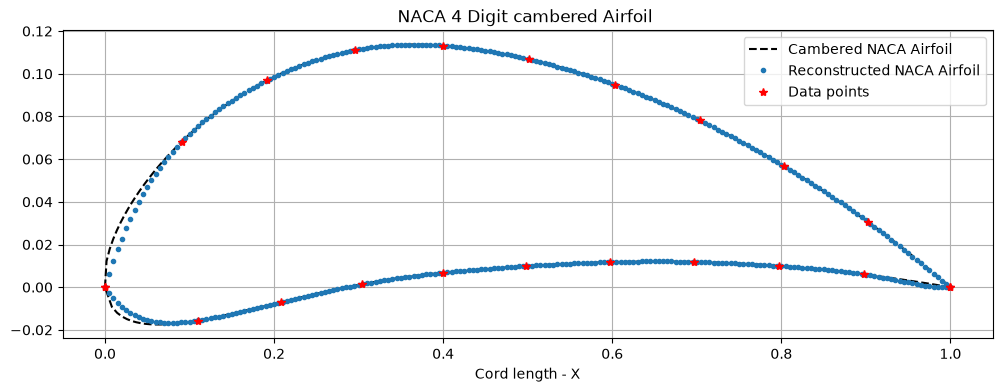

In [7]:
mp.figure(figsize=(12, 4))
mp.plot(X,Y, '--',color='k',label = 'Cambered NACA Airfoil')
mp.plot(X_a,Y_a,'.',label = 'Reconstructed NACA Airfoil')
mp.plot(X_test,Y_test,'*',color='r',label = 'Data points')
mp.title('NACA 4 Digit cambered Airfoil ')
mp.xlabel('Cord length - X')
mp.legend()
mp.grid()
mp.show()
mp.show()

#mp.plot(x,y_c,'--',label = 'Cambered line')

Maximum Error % =  0.8868548342308615
RMS Error % =  0.1676694576609634
Maximum Error % =  1.1027224238827478
RMS Error % =  0.2706091925194294
Maximum Error % =  1.3786104937767627
RMS Error % =  0.3882039970271545
Maximum Error % =  3.036959753250649
RMS Error % =  1.3343448217969538


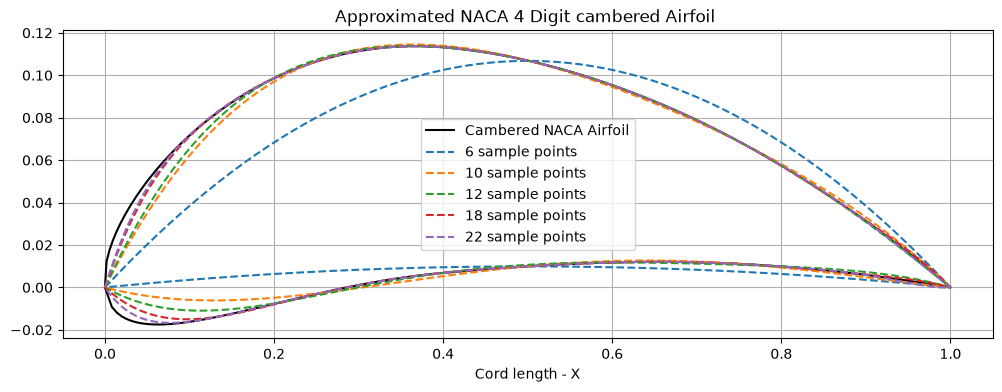

In [8]:
x_upper = np.array([X[0],X[25],X[50],X[75],X[100],X[125],X[150],X[175],X[200]])
y_upper = np.array([Y[0],Y[25],Y[50],Y[75],Y[100],Y[125],Y[150],Y[175],Y[200]])

x_lower = np.array([X[201],X[226],X[251],X[276],X[301],X[326],X[351],X[376],X[401]])
y_lower = np.array([Y[201],Y[226],Y[251],Y[276],Y[301],Y[326],Y[351],Y[376],Y[401]])


Yupper= Lagrng(x_upper,y_upper,9,Xupper)
Ylower= Lagrng(x_lower,y_lower,9,Xlower)

X_18= np.concatenate([Xupper,Xlower])
Y_18= np.concatenate([Yupper,Ylower])

Y_difference = Y - Y_18
max_error18 = np.max(np.abs(Y_difference))
print("Maximum Error % = ",max_error18*100)
rms_error18 = np.sqrt(np.mean(Y_difference ** 2))
print("RMS Error % = ",rms_error18*100)

#-------------------------------------------

x_upper = np.array([X[0],X[40],X[80],X[120],X[160],X[200]])
y_upper = np.array([Y[0],Y[40],Y[80],Y[120],Y[160],Y[200]])

x_lower = np.array([X[201],X[241],X[281],X[321],X[361],X[401]])
y_lower = np.array([Y[201],Y[241],Y[281],Y[321],Y[361],Y[401]])

Yupper= Lagrng(x_upper,y_upper,6,Xupper)
Ylower= Lagrng(x_lower,y_lower,6,Xlower)

X_12= np.concatenate([Xupper,Xlower])
Y_12= np.concatenate([Yupper,Ylower])

Y_difference = Y - Y_12
max_error12 = np.max(np.abs(Y_difference))
print("Maximum Error % = ",max_error12*100)
rms_error12 = np.sqrt(np.mean(Y_difference ** 2))
print("RMS Error % = ",rms_error12*100)

#--------------------------------------------

x_upper = np.array([X[0],X[50],X[100],X[150],X[200]])
y_upper = np.array([Y[0],Y[50],Y[100],Y[150],Y[200]])

x_lower = np.array([X[201],X[251],X[301],X[351],X[401]])
y_lower = np.array([Y[201],Y[251],Y[301],Y[351],Y[401]])


Yupper= Lagrng(x_upper,y_upper,5,Xupper)
Ylower= Lagrng(x_lower,y_lower,5,Xlower)

X_10= np.concatenate([Xupper,Xlower])
Y_10= np.concatenate([Yupper,Ylower])

Y_difference = Y - Y_10
max_error10 = np.max(np.abs(Y_difference))
print("Maximum Error % = ",max_error10*100)
rms_error10 = np.sqrt(np.mean(Y_difference ** 2))
print("RMS Error % = ",rms_error10*100)

#------------------------------------------

x_upper = np.array([X[0],X[100],X[200]])
y_upper = np.array([Y[0],Y[100],Y[200]])

x_lower = np.array([X[201],X[301],X[401]])
y_lower = np.array([Y[201],Y[301],Y[401]])

Yupper= Lagrng(x_upper,y_upper,3,Xupper)
Ylower= Lagrng(x_lower,y_lower,3,Xlower)

X_06= np.concatenate([Xupper,Xlower])
Y_06= np.concatenate([Yupper,Ylower])

Y_difference = Y - Y_06
max_error06 = np.max(np.abs(Y_difference))
print("Maximum Error % = ",max_error06*100)
rms_error06 = np.sqrt(np.mean(Y_difference ** 2))
print("RMS Error % = ",rms_error06*100)

#-------------------------------------------

mp.figure(figsize=(12, 4))
mp.plot(X,Y,color='k',label = 'Cambered NACA Airfoil')
mp.plot(X_06,Y_06, '--',label='6 sample points')
mp.plot(X_10,Y_10, '--',label='10 sample points')
mp.plot(X_12,Y_12, '--',label='12 sample points')
mp.plot(X_18,Y_18, '--',label='18 sample points')
mp.plot(X_a,Y_a, '--',label='22 sample points')
#mp.plot(x,y_c,'--')
mp.title('Approximated NACA 4 Digit cambered Airfoil ')
mp.xlabel('Cord length - X')
mp.legend()
mp.grid()
mp.show()


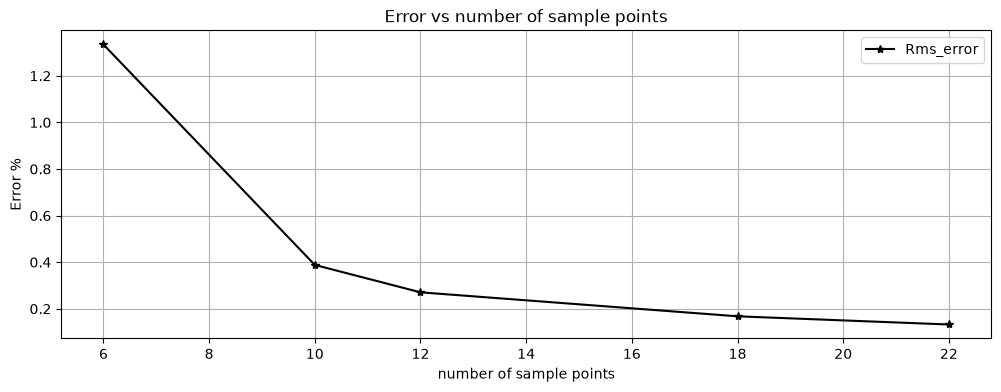

In [9]:
error_rms = np.array([rms_error06,rms_error10,rms_error12,rms_error18,rms_error])
error_max = np.array([max_error06,max_error10,max_error12,max_error18,max_error])
n         = np.array([6,10,12,18,22])

mp.figure(figsize=(12, 4))
mp.plot(n,error_rms*100,'-*',color='k',label='Rms_error')
#mp.plot(n,error_max,'-',label='Max_error')
mp.title('Error vs number of sample points')
mp.xlabel('number of sample points')
mp.ylabel('Error %')
mp.legend()
mp.grid()

### Obtaining a smooth leading-edge curvature 
    Even though the function efficiency improves with additional sample points, if we observe the leading-edge curvature closely,
    it doesn't change much and tends to have a sharper edge. This can be mitigated by clustering the sample points close to the leading and trailing edge

### Implementing Cubic Spline 


In [10]:

def cubic_spline(x, a, b, c, d, X_1):

    interval = len(x) - 1
    for i in range(interval):
        if x[i] <= X_1 <= x[i + 1]:
            dx = X_1 - x[i]
            y_1 = (a[i] + b[i]*dx + c[i]*dx**2 + d[i]*dx**3)
            return y_1


In [11]:
def Cubic_spline_interpolation(X_s,Y_s):
        
    h = np.diff(x) 
    n = len(x) - 1 
    A = np.zeros((n - 1, n - 1))
    z = np.zeros(n - 1)

    for i in range(1, n):
        row = i - 1
        A[row, row] = 2 * (h[i - 1] + h[i]) #Zi
        if i > 1:
            A[row, row - 1] = h[i - 1] #Z(i-1)
        if i < n - 1:
            A[row, row + 1] = h[i] #Z(i+1)
    
        z[row] = 6 * ((y[i + 1] - y[i]) / h[i]- (y[i] - y[i - 1]) / h[i - 1])
        
    Zin = np.linalg.solve(A, z)
    Z = np.zeros(n + 1)
    Z[1:n] = Zin
    
    a = np.zeros(n)
    b = np.zeros(n)
    c = np.zeros(n)
    d = np.zeros(n)
    
    for i in range(n):
        a[i] = y[i]
        c[i] = Z[i] / 2
        d[i] = (Z[i + 1] - Z[i]) / (6 * h[i])
        b[i] = ((y[i + 1] - y[i]) / h[i]- h[i] * (2 * Z[i] + Z[i + 1]) / 6)
    
    x_low = np.linspace(0, 1, 200)
    y_new = np.zeros(len(x_low))
    
    for j in range(len(x_low)):
        y_new[j] = cubic_spline(x, a, b, c, d, x_low[j])
    
    #mp.figure(figsize=(12, 4))
    #mp.plot(x_low, y_low)
    return y_new

In [12]:
# for lower surface
x_up  = np.linspace(0,1,200)
x_low = np.linspace(0, 1, 200)
x_low = np.flip(x_low)
x_airfoil = np.concatenate([x_up,x_low])
#=============================================================================
x= np.array([X[0],X[25],X[50],X[75],X[100],X[125],X[150],X[175],X[200]])
y = np.array([Y[0],Y[25],Y[50],Y[75],Y[100],Y[125],Y[150],Y[175],Y[200]])
y_up = Cubic_spline_interpolation(x,y)

x = np.array([x_l[0], x_l[25], x_l[50], x_l[75], x_l[100],x_l[125], x_l[150], x_l[175], x_l[200]])
y = np.array([y_l[0], y_l[25], y_l[50], y_l[75], y_l[100],y_l[125], y_l[150], y_l[175], y_l[200]])

y_low = Cubic_spline_interpolation(x,y)
y_low = np.flip(y_low)
y_airfoil1 = np.concatenate([y_up,y_low])
#=============================================================================
x = np.array([X[0],X[40],X[80],X[120],X[160],X[200]])
y = np.array([Y[0],Y[40],Y[80],Y[120],Y[160],Y[200]])
y_up = Cubic_spline_interpolation(x,y)

x = np.array([x_l[0], x_l[40], x_l[80], x_l[120], x_l[160],x_l[200]])
y = np.array([y_l[0], y_l[40], y_l[80], y_l[120], y_l[160],y_l[200]])

y_low = Cubic_spline_interpolation(x,y)
y_low = np.flip(y_low)
y_airfoil2 = np.concatenate([y_up,y_low])
#=============================================================================
x = np.array([X[0],X[20],X[40],X[60],X[80],X[100],X[120],X[140],X[160],X[180],X[200]])
y = np.array([Y[0],Y[20],Y[40],Y[60],Y[80],Y[100],Y[120],Y[140],Y[160],Y[180],Y[200]])
y_up = Cubic_spline_interpolation(x,y)

x = np.array([x_l[0], x_l[20], x_l[40], x_l[60], x_l[80], x_l[100],x_l[120], x_l[140], x_l[160], x_l[180], x_l[200]])
y = np.array([y_l[0], y_l[20], y_l[40], y_l[60], y_l[80], y_l[100],y_l[120], y_l[140], y_l[160], y_l[180], y_l[200]])

y_low = Cubic_spline_interpolation(x,y)
y_low = np.flip(y_low)
y_airfoil3 = np.concatenate([y_up,y_low])

#=============================================================================
x = np.array([X[0], X[5], X[10], X[15], X[20], X[25], X[30], X[35], X[40], X[45],
              X[50], X[55], X[60], X[65], X[70], X[75], X[80], X[85], X[90], X[95],
              X[100], X[105], X[110], X[115], X[120], X[125], X[130], X[135], X[140], X[145],
              X[150], X[155], X[160], X[165], X[170], X[175], X[180], X[185], X[190], X[195],
              X[200]])

y = np.array([Y[0], Y[5], Y[10], Y[15], Y[20], Y[25], Y[30], Y[35], Y[40], Y[45],
              Y[50], Y[55], Y[60], Y[65], Y[70], Y[75], Y[80], Y[85], Y[90], Y[95],
              Y[100], Y[105], Y[110], Y[115], Y[120], Y[125], Y[130], Y[135], Y[140], Y[145],
              Y[150], Y[155], Y[160], Y[165], Y[170], Y[175], Y[180], Y[185], Y[190], Y[195],
              Y[200]])

y_up = Cubic_spline_interpolation(x,y)

x = np.array([x_l[0], x_l[5], x_l[10], x_l[15], x_l[20], x_l[25], x_l[30], x_l[35], x_l[40], x_l[45],
              x_l[50], x_l[55], x_l[60], x_l[65], x_l[70], x_l[75], x_l[80], x_l[85], x_l[90], x_l[95],
              x_l[100], x_l[105], x_l[110], x_l[115], x_l[120], x_l[125], x_l[130], x_l[135], x_l[140], x_l[145],
              x_l[150], x_l[155], x_l[160], x_l[165], x_l[170], x_l[175], x_l[180], x_l[185], x_l[190], x_l[195],
              x_l[200]])

y = np.array([y_l[0], y_l[5], y_l[10], y_l[15], y_l[20], y_l[25], y_l[30], y_l[35], y_l[40], y_l[45],
              y_l[50], y_l[55], y_l[60], y_l[65], y_l[70], y_l[75], y_l[80], y_l[85], y_l[90], y_l[95],
              y_l[100], y_l[105], y_l[110], y_l[115], y_l[120], y_l[125], y_l[130], y_l[135], y_l[140], y_l[145],
              y_l[150], y_l[155], y_l[160], y_l[165], y_l[170], y_l[175], y_l[180], y_l[185], y_l[190], y_l[195],
              y_l[200]])
y_low = Cubic_spline_interpolation(x,y)
y_low = np.flip(y_low)
y_airfoil4 = np.concatenate([y_up,y_low])
print(len(x))

#=============================================================================

x = np.array([X[0],X[100],X[200]])
y = np.array([Y[0],Y[100],Y[200]])
y_up = Cubic_spline_interpolation(x,y)

x = np.array([x_l[0], x_l[100],x_l[200]])
y = np.array([y_l[0], y_l[100],y_l[200]])

y_low = Cubic_spline_interpolation(x,y)
y_low = np.flip(y_low)
y_airfoil5 = np.concatenate([y_up,y_low])

41


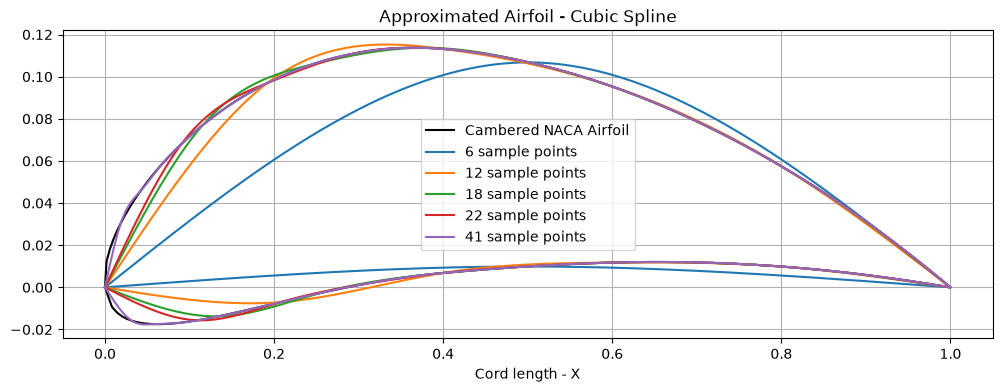

In [13]:
mp.figure(figsize=(12, 4))
mp.plot(X,Y,color='k',label = 'Cambered NACA Airfoil')
mp.plot(x_airfoil,y_airfoil5,label='6 sample points')
mp.plot(x_airfoil,y_airfoil2,label='12 sample points')
mp.plot(x_airfoil,y_airfoil1,label='18 sample points')
mp.plot(x_airfoil,y_airfoil3,label='22 sample points')
mp.plot(x_airfoil,y_airfoil4,label='41 sample points')
mp.title('Approximated Airfoil - Cubic Spline')
mp.xlabel('Cord length - X')
mp.legend()
mp.grid()
mp.show()

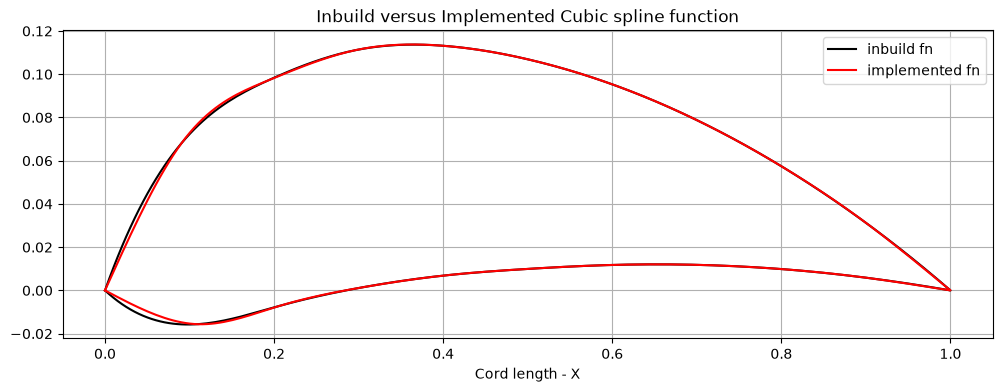

In [14]:
from scipy.interpolate import CubicSpline, interp1d


x1 = np.array([X[0],X[20],X[40],X[60],X[80],X[100],X[120],X[140],X[160],X[180],X[200]])
y1 = np.array([Y[0],Y[20],Y[40],Y[60],Y[80],Y[100],Y[120],Y[140],Y[160],Y[180],Y[200]])


x2 = np.array([x_l[0], x_l[20], x_l[40], x_l[60], x_l[80], x_l[100],x_l[120], x_l[140], x_l[160], x_l[180], x_l[200]])
y2 = np.array([y_l[0], y_l[20], y_l[40], y_l[60], y_l[80], y_l[100],y_l[120], y_l[140], y_l[160], y_l[180], y_l[200]])

cs1 = CubicSpline(x1,y1)
cs2 = CubicSpline(x2,y2)

x_up  = np.linspace(0,1,200)
y_up  = cs1(x_up)

x_low = np.linspace(0,1,200)
y_low = cs2(x_low)

x_low = np.flip(x_low)
y_low = np.flip(y_low)

X_s  = np.concatenate([x_up,x_low])
Y_s  = np.concatenate([y_up,y_low])

mp.figure(figsize=(12, 4))
# mp.plot(x_up,y_up)
# mp.plot(x_low,y_low)
mp.plot(X_s,Y_s,color='k',label='inbuild fn')
mp.plot(x_airfoil,y_airfoil3,color='r',label='implemented fn')
mp.title('Inbuild versus Implemented Cubic spline function')
mp.xlabel('Cord length - X')
mp.legend()
mp.grid()
mp.show()

### Conclusion:

1. **NACA Airfoil Generation:**  
   A cambered NACA 4-digit airfoil was generated using randomly selected values of maximum camber, the values were kept within the specified range. The airfoil geometry was reconstructed using its upper and lower surface coordinates.

2. **Lagrange Interpolation:**  
   We implemented the Lagrange interpolation method to reconstruct the airfoil using a limited number of sample points. We compared the reconstructed profile with the original geometry and calculated the maximum absolute error and root mean square (RMS) error. For the reconstruction with 6 points, the RMS error was approximately *1.61% of the chord*. Increasing the number of sample points generally improved the accuracy of the reconstructed airfoil. However, uniformly spaced points did not adequately capture the curvature near the leading edge. Clustering sample points near the leading and trailing edges can improve the representation of regions with higher curvature.

4. **Cubic Spline Interpolation:**  
   A cubic spline interpolation function was implemented using a system of linear equations to determine the second derivatives at the interpolation points. The resulting coefficients were used to construct piecewise cubic polynomials. Reconstructions were obtained using different numbers of sample points, and the resulting profiles were compared with the original airfoil geometry. The implemented spline was also compared graphically with the built-in cubic spline function from SciPy.

 
The work demonstrates how interpolation techniques can be used to reconstruct airfoil geometry from a limited set of coordinate points. Both Lagrange interpolation and cubic spline interpolation provide approaches to approximating the original profile, while the accuracy of the reconstruction depends on the interpolation method, the number of sample points, and their distribution along the airfoil surface.

### References

1) Introduction to matplotlib.ipynb 
2) Introduction to numpy.ipynb
3) Wikipedia contributors, “NACA airfoil,” Wikipedia. [Online]. Available: https://en.wikipedia.org/wiki/NACA_airfoil.
4) Wikipedia contributors, “Lagrange polynomial,” Wikipedia. [Online]. Available: https://en.wikipedia.org/wiki/Lagrange_polynomial.
5) GeeksforGeeks, “Cubic spline interpolation,” GeeksforGeeks. [Online]. Available: https://www.geeksforgeeks.org/machine-learning/cubic-spline-interpolation/.
6) W. H. Press, S. A. Teukolsky, W. T. Vetterling, and B. P. Flannery, Numerical Recipes in Fortran 90: The Art of Scientific Computing, 2nd ed. Cambridge, U.K.: Cambridge University Press, 1996.
